In [267]:
import matplotlib.pyplot as plt
import time
import random

In [268]:
# PART 1: PRODUCTION RULES

rules = [
    {
        "id": "R1",
        "conditions": ["fever", "cough"],
        "conclusion": "flu"
    },

    {
        "id": "R2",
        "conditions": ["fever", "headache"],
        "conclusion": "infection"
    },

    {
        "id": "R3",
        "conditions": ["cough"],
        "conclusion": "breathing_problem"
    },

    {
        "id": "R4",
        "conditions": ["flu", "weakness"],
        "conclusion": "rest"
    }
]


# PART 2: WORKING MEMORY

working_memory = {
    "fever",
    "cough"
}


In [269]:
# FUNCTION 1: BASIC MATCHER


def find_conflict_set(rules, working_memory):

    conflict_set = []

    # Check every rule
    for rule in rules:

        all_conditions_present = True

        # Check every condition of the rule
        for condition in rule["conditions"]:

            if condition not in working_memory:
                all_conditions_present = False
                break

        # Check refractoriness
        # Rule should not match if conclusion
        # is already present in working memory

        if all_conditions_present:

            if rule["conclusion"] not in working_memory:

                conflict_set.append(rule["id"])

    return conflict_set


In [270]:
# PART 3: DISPLAY BASIC MATCH RESULT

print("EXPERIMENT 2: PRODUCTION RULES AND MATCH PHASE")


print("\nWorking Memory:")
print(working_memory)

conflict_set = find_conflict_set(
    rules,
    working_memory
)

print("\nConflict Set:")
print(conflict_set)

EXPERIMENT 2: PRODUCTION RULES AND MATCH PHASE

Working Memory:
{'cough', 'fever'}

Conflict Set:
['R1', 'R3']


In [271]:
# PART 4: DISPLAY EACH RULE RESULT


print("RULE MATCHING DETAILS")


for rule in rules:

    all_conditions_present = True

    for condition in rule["conditions"]:

        if condition not in working_memory:
            all_conditions_present = False
            break

    conclusion_present = (
        rule["conclusion"] in working_memory
    )

    print("\nRule:", rule["id"])

    print("Conditions:", rule["conditions"])

    print("Conclusion:", rule["conclusion"],"\n")

    if all_conditions_present:
        print("All conditions satisfied: YES")
    else:
        print("All conditions satisfied: NO")

    if conclusion_present:
        print("Conclusion already in WM: YES")
    else:
        print("Conclusion already in WM: NO")

    if all_conditions_present and not conclusion_present:
        print("Result: MATCH")
    else:
        print("Result: NO MATCH")



RULE MATCHING DETAILS

Rule: R1
Conditions: ['fever', 'cough']
Conclusion: flu 

All conditions satisfied: YES
Conclusion already in WM: NO
Result: MATCH

Rule: R2
Conditions: ['fever', 'headache']
Conclusion: infection 

All conditions satisfied: NO
Conclusion already in WM: NO
Result: NO MATCH

Rule: R3
Conditions: ['cough']
Conclusion: breathing_problem 

All conditions satisfied: YES
Conclusion already in WM: NO
Result: MATCH

Rule: R4
Conditions: ['flu', 'weakness']
Conclusion: rest 

All conditions satisfied: NO
Conclusion already in WM: NO
Result: NO MATCH


In [272]:
# PART 5: EXERCISE 1
# Add facts one at a time and observe conflict set

print("EXERCISE 1")
print("Adding Facts One at a Time")

exercise_rules = [
    {
        "id": "R1",
        "conditions": ["fever", "cough"],
        "conclusion": "flu"
    },

    {
        "id": "R2",
        "conditions": ["fever", "headache"],
        "conclusion": "infection"
    },

    {
        "id": "R3",
        "conditions": ["cough"],
        "conclusion": "breathing_problem"
    }
]


working_memory_exercise = set()


facts_to_add = [
    "fever",
    "cough",
    "headache"
]


for fact in facts_to_add:

    

    print("\nAdding fact:", fact)

    working_memory_exercise.add(fact)

    print("Working Memory:")
    print(working_memory_exercise)

    conflict_set = find_conflict_set(
        exercise_rules,
        working_memory_exercise
    )

    print("Conflict Set:")
    print(conflict_set)



EXERCISE 1
Adding Facts One at a Time

Adding fact: fever
Working Memory:
{'fever'}
Conflict Set:
[]

Adding fact: cough
Working Memory:
{'cough', 'fever'}
Conflict Set:
['R1', 'R3']

Adding fact: headache
Working Memory:
{'cough', 'fever', 'headache'}
Conflict Set:
['R1', 'R2', 'R3']


In [273]:
# PART 6: TEST REFRACTORINESS

print("REFRACTORINESS TEST")



refraction_rules = [
    {
        "id": "R1",
        "conditions": ["fever", "cough"],
        "conclusion": "flu"
    },

    {
        "id": "R2",
        "conditions": ["cough"],
        "conclusion": "breathing_problem"
    }
]


working_memory_refraction = {
    "fever",
    "cough"
}


print("\nBefore adding conclusion:")

print("Working Memory:")
print(working_memory_refraction)

conflict_set = find_conflict_set(
    refraction_rules,
    working_memory_refraction
)

print("Conflict Set:")
print(conflict_set)


# Add conclusion of R1
working_memory_refraction.add("flu")


print("\nAfter adding 'flu' to Working Memory:")

print("Working Memory:")
print(working_memory_refraction)

conflict_set = find_conflict_set(
    refraction_rules,
    working_memory_refraction
)

print("Conflict Set:")
print(conflict_set)



REFRACTORINESS TEST

Before adding conclusion:
Working Memory:
{'cough', 'fever'}
Conflict Set:
['R1', 'R2']

After adding 'flu' to Working Memory:
Working Memory:
{'cough', 'fever', 'flu'}
Conflict Set:
['R2']


In [274]:


# PART 7: EXERCISE 2
# Support NOT fact



print("EXERCISE 2")
print("Support for NOT fact")



not_rules = [

    {
        "id": "R1",
        "conditions": ["fever", "cough"],
        "conclusion": "flu"
    },

    {
        "id": "R2",
        "conditions": ["fever", "NOT headache"],
        "conclusion": "possible_infection"
    },

    {
        "id": "R3",
        "conditions": ["NOT cough"],
        "conclusion": "no_cough"
    },

    {
        "id": "R4",
        "conditions": ["cough", "NOT headache"],
        "conclusion": "respiratory_problem"
    }
]


working_memory_not = {
    "fever",
    "cough"
}



# FUNCTION 2: MATCHER WITH NOT SUPPORT


def find_conflict_set_with_not(rules, working_memory):

    conflict_set = []

    for rule in rules:

        all_conditions_present = True

        for condition in rule["conditions"]:

            
            # Positive condition
             

            if not condition.startswith("NOT "):

                if condition not in working_memory:

                    all_conditions_present = False
                    break

             
            # Negative condition
             

            else:

                fact = condition[4:]

                if fact in working_memory:

                    all_conditions_present = False
                    break

         
        # Refractoriness
         

        if all_conditions_present:

            if rule["conclusion"] not in working_memory:

                conflict_set.append(rule["id"])

    return conflict_set


print("\nWorking Memory:")
print(working_memory_not)

conflict_set = find_conflict_set_with_not(
    not_rules,
    working_memory_not
)

print("\nConflict Set:")
print(conflict_set)



# TEST DIFFERENT WORKING MEMORIES FOR NOT

print("Testing NOT Conditions")



test_memories = [

    {
        "fever"
    },

    {
        "fever",
        "cough"
    },

    {
        "fever",
        "headache"
    },

    {
        "cough"
    },

    set()
]


for wm in test_memories:

    

    print("Working Memory:")
    print(wm)

    conflict_set = find_conflict_set_with_not(
        not_rules,
        wm
    )

    print("Conflict Set:")
    print(conflict_set)



EXERCISE 2
Support for NOT fact

Working Memory:
{'cough', 'fever'}

Conflict Set:
['R1', 'R2', 'R4']
Testing NOT Conditions
Working Memory:
{'fever'}
Conflict Set:
['R2', 'R3']
Working Memory:
{'cough', 'fever'}
Conflict Set:
['R1', 'R2', 'R4']
Working Memory:
{'fever', 'headache'}
Conflict Set:
['R3']
Working Memory:
{'cough'}
Conflict Set:
['R4']
Working Memory:
set()
Conflict Set:
['R3']


In [275]:


# PART 8: EXERCISE 3
# 1,000 AUTO-GENERATED RULES



print("EXERCISE 3")
print("Performance Test with 1,000 Rules")

# Generate 1,000 rules


large_rules = []


for i in range(1000):

    rule = {
        "id": "R" + str(i + 1),

        "conditions": [
            "fact" + str(random.randint(0,1000)),
            "fact" + str(random.randint(0,1000))
        ],

        "conclusion": "conclusion" + str(random.randint(0,1000))
    }


    large_rules.append(rule)



# Generate Working Memory


large_working_memory = set()


for i in range(1000):

    if random.random()<0.7:

        large_working_memory.add(
        "fact" + str(i)
    )



# Measure Matching Time


start_time = time.perf_counter()


large_conflict_set = find_conflict_set(
    large_rules,
    large_working_memory
)


end_time = time.perf_counter()


match_time = end_time - start_time


print("\nNumber of Rules:")
print(len(large_rules))

print("\nNumber of Facts:")
print(len(large_working_memory))

print("\nNumber of Matching Rules:")
print(len(large_conflict_set))

print("\nMatch Time:")
print(match_time, "seconds")


EXERCISE 3
Performance Test with 1,000 Rules

Number of Rules:
1000

Number of Facts:
710

Number of Matching Rules:
497

Match Time:
0.0005073000211268663 seconds


SCALING TEST


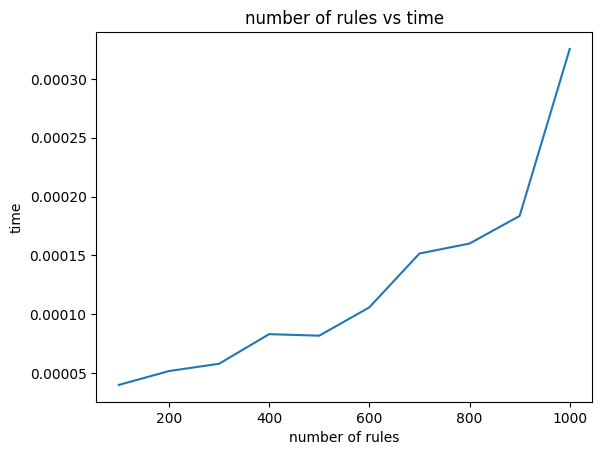

In [ ]:
# PART 10: TEST DIFFERENT NUMBERS OF RULES

print("SCALING TEST")

rule_sizes = [100,200,300,400,500,600,700,800,900,1000]
times=[]


for size in rule_sizes:

    test_rules = []

    for i in range(size):

        rule = {
            "id": "R" + str(i + 1),

            "conditions": [
                "fact" + str(random.randint(0,1000)),
                "fact" + str(random.randint(0,1000))
            ],

            "conclusion": "conclusion" + str(random.randint(0,1000))
        }

        test_rules.append(rule)


    
    # Generate working memory
    

    test_working_memory = set()

    for i in range(size):

        test_working_memory.add(
            "fact" + str(i)
        )

    start_time = time.perf_counter()


    test_conflict_set = find_conflict_set(
        test_rules,
        test_working_memory
    )


    end_time = time.perf_counter()


    elapsed_time = end_time - start_time

    times.append(elapsed_time)


plt.plot(rule_sizes, times)
plt.xlabel("number of rules")
plt.ylabel("time")
plt.title("number of rules vs time")
plt.show()



# Experiment 2: Production Rules and the Match Phase

**Aim:** To represent domain knowledge as IF–THEN production rules, hold facts in a working memory (WM), and compute the conflict set of applicable rules.

## Theory

A **production system** has three parts:

1. **Rule base** — a set of IF–THEN productions (rules).
2. **Working memory (WM)** — the set of facts currently believed to be true.
3. **Inference engine** — runs the **recognise–act cycle**:
   - **Match**: compare every rule's conditions against WM.
   - **Select**: choose one rule from the resulting *conflict set*.
   - **Act**: execute (fire) that rule's conclusion, which usually changes WM.
   - Repeat.

This experiment isolates the **match phase** only (rule *selection strategy* is Experiment 5).

A rule is **applicable** ("matches") when:
- every condition in its IF part is present in WM, **and**
- its conclusion is **not already** in WM (this is called **refractoriness** — it stops a rule from firing again and again on data that hasn't changed).

The set of all applicable rules at a given moment is called the **conflict set**.

## Algorithm

1. Encode each rule as a record: `(id, conditions, conclusion)`.
2. Initialise working memory as a set of facts.
3. For each rule, test whether all its conditions are members of WM **and** its conclusion is absent from WM.
4. Collect and display the conflict set.


## Step 1: Represent a Rule

We use a small `Rule` class with:
- `rid` — a human-readable identifier (e.g. `"R1"`)
- `conditions` — a set/list of facts that must ALL be true
- `conclusion` — the single fact this rule would add if it fires

We keep it deliberately simple (a `namedtuple`-like class) so the match logic is easy to read.


In [277]:
from dataclasses import dataclass, field
from typing import List, Set

@dataclass
class Rule:
    rid: str                 # rule identifier, e.g. "R1"
    conditions: List[str]    # IF-part: every one of these must be in WM
    conclusion: str          # THEN-part: the fact this rule would assert

    def __repr__(self):
        cond_str = " AND ".join(self.conditions)
        return f"{self.rid}: IF {cond_str} THEN {self.conclusion}"


## Step 2: Define the Knowledge Base (Rules) and Initial Working Memory

We'll use a small **animal identification** rule base — a classic production-system teaching example.

| Rule | IF (conditions)                          | THEN (conclusion)     |
|------|-------------------------------------------|------------------------|
| R1   | has_hair                                  | is_mammal              |
| R2   | gives_milk                                | is_mammal              |
| R3   | is_mammal, eats_meat                      | is_carnivore           |
| R4   | is_mammal, has_pointed_teeth, has_claws   | is_carnivore           |
| R5   | is_carnivore, has_tawny_color, has_dark_spots | is_cheetah         |
| R6   | is_carnivore, has_tawny_color, has_black_stripes | is_tiger        |
| R7   | is_mammal, has_hooves                     | is_ungulate            |
| R8   | is_mammal, chews_cud                      | is_ungulate            |
| R9   | is_ungulate, has_long_neck, has_long_legs | is_giraffe              |
| R10  | is_ungulate, has_black_stripes            | is_zebra                |


In [278]:
rules = [
    Rule("R1", ["has_hair"], "is_mammal"),
    Rule("R2", ["gives_milk"], "is_mammal"),
    Rule("R3", ["is_mammal", "eats_meat"], "is_carnivore"),
    Rule("R4", ["is_mammal", "has_pointed_teeth", "has_claws"], "is_carnivore"),
    Rule("R5", ["is_carnivore", "has_tawny_color", "has_dark_spots"], "is_cheetah"),
    Rule("R6", ["is_carnivore", "has_tawny_color", "has_black_stripes"], "is_tiger"),
    Rule("R7", ["is_mammal", "has_hooves"], "is_ungulate"),
    Rule("R8", ["is_mammal", "chews_cud"], "is_ungulate"),
    Rule("R9", ["is_ungulate", "has_long_neck", "has_long_legs"], "is_giraffe"),
    Rule("R10", ["is_ungulate", "has_black_stripes"], "is_zebra"),
]

# Initial working memory: only raw, observed facts about some animal
working_memory: Set[str] = {
    "has_hair",
    "eats_meat",
    "has_tawny_color",
    "has_black_stripes",
}

print("Rule base:")
for r in rules:
    print(" ", r)

print("\nInitial WM:", working_memory)


Rule base:
  R1: IF has_hair THEN is_mammal
  R2: IF gives_milk THEN is_mammal
  R3: IF is_mammal AND eats_meat THEN is_carnivore
  R4: IF is_mammal AND has_pointed_teeth AND has_claws THEN is_carnivore
  R5: IF is_carnivore AND has_tawny_color AND has_dark_spots THEN is_cheetah
  R6: IF is_carnivore AND has_tawny_color AND has_black_stripes THEN is_tiger
  R7: IF is_mammal AND has_hooves THEN is_ungulate
  R8: IF is_mammal AND chews_cud THEN is_ungulate
  R9: IF is_ungulate AND has_long_neck AND has_long_legs THEN is_giraffe
  R10: IF is_ungulate AND has_black_stripes THEN is_zebra

Initial WM: {'eats_meat', 'has_tawny_color', 'has_black_stripes', 'has_hair'}


## Step 3 & 4: The Match Phase — Computing the Conflict Set

For each rule we check:

1. **All conditions satisfied?** — `set(rule.conditions).issubset(WM)`
2. **Refractoriness** — `rule.conclusion not in WM` (don't refire a rule whose conclusion already holds)

If both hold, the rule is *applicable* and goes into the conflict set.


In [279]:
def match(rules: List[Rule], wm: Set[str]) -> List[Rule]:
    """Return the conflict set: rules whose conditions all hold in WM
    and whose conclusion is not already in WM (refractoriness)."""
    conflict_set = []
    for rule in rules:
        conditions_met = set(rule.conditions).issubset(wm)
        not_already_known = rule.conclusion not in wm
        if conditions_met and not_already_known:
            conflict_set.append(rule)
    return conflict_set


def show_conflict_set(rules, wm):
    cs = match(rules, wm)
    print("WM =", sorted(wm))
    if cs:
        print("Conflict set:")
        for r in cs:
            print("  ->", r)
    else:
        print("Conflict set: EMPTY (no rule currently applicable)")
    print()
    return cs

cs = show_conflict_set(rules, working_memory)


WM = ['eats_meat', 'has_black_stripes', 'has_hair', 'has_tawny_color']
Conflict set:
  -> R1: IF has_hair THEN is_mammal



## Step 6 & 7: Run the Recognise Phase and Modify Facts

Let's simulate part of a recognise–act cycle *by hand*: fire `R1` (add `is_mammal`), recompute
the conflict set, then fire `R3` (add `is_carnivore`), and so on — watching the conflict set
change at each step, exactly as the Observations section describes.


In [280]:
def fire(rule: Rule, wm: Set[str]) -> Set[str]:
    """Act phase: apply a rule's conclusion to WM."""
    new_wm = set(wm)
    new_wm.add(rule.conclusion)
    print(f"Firing {rule.rid} -> asserting '{rule.conclusion}'")
    return new_wm

wm = set(working_memory)
print("=== Cycle 0 ===")
cs = show_conflict_set(rules, wm)

step = 1
while cs:
    print(f"=== Cycle {step}: firing first rule in conflict set ===")
    wm = fire(cs[0], wm)
    cs = show_conflict_set(rules, wm)
    step += 1

print("Final WM:", sorted(wm))


=== Cycle 0 ===
WM = ['eats_meat', 'has_black_stripes', 'has_hair', 'has_tawny_color']
Conflict set:
  -> R1: IF has_hair THEN is_mammal

=== Cycle 1: firing first rule in conflict set ===
Firing R1 -> asserting 'is_mammal'
WM = ['eats_meat', 'has_black_stripes', 'has_hair', 'has_tawny_color', 'is_mammal']
Conflict set:
  -> R3: IF is_mammal AND eats_meat THEN is_carnivore

=== Cycle 2: firing first rule in conflict set ===
Firing R3 -> asserting 'is_carnivore'
WM = ['eats_meat', 'has_black_stripes', 'has_hair', 'has_tawny_color', 'is_carnivore', 'is_mammal']
Conflict set:
  -> R6: IF is_carnivore AND has_tawny_color AND has_black_stripes THEN is_tiger

=== Cycle 3: firing first rule in conflict set ===
Firing R6 -> asserting 'is_tiger'
WM = ['eats_meat', 'has_black_stripes', 'has_hair', 'has_tawny_color', 'is_carnivore', 'is_mammal', 'is_tiger']
Conflict set: EMPTY (no rule currently applicable)

Final WM: ['eats_meat', 'has_black_stripes', 'has_hair', 'has_tawny_color', 'is_carnivore

Notice how the conflict set **shrinks and grows** as facts accumulate — new facts
(like `is_mammal`) can make previously-inapplicable rules (like `R3`, `R4`, `R7`, `R8`) match,
while refractoriness prevents `R1`/`R2` from firing again once `is_mammal` is already known.
This is exactly the behaviour described in the Observations section.


---
## Exercise 1: Add Facts to WM One at a Time

We start from an empty WM and add one raw fact at a time, printing the conflict set after each
addition, so we can see it grow (and shrink, via refractoriness) incrementally.


In [281]:
facts_in_order = [
    "has_hair",
    "eats_meat",
    "has_tawny_color",
    "has_black_stripes",
]

wm_ex1: Set[str] = set()
print("--- Exercise 1: incremental fact addition ---\n")
for f in facts_in_order:
    wm_ex1.add(f)
    print(f"Added fact: '{f}'")
    show_conflict_set(rules, wm_ex1)


--- Exercise 1: incremental fact addition ---

Added fact: 'has_hair'
WM = ['has_hair']
Conflict set:
  -> R1: IF has_hair THEN is_mammal

Added fact: 'eats_meat'
WM = ['eats_meat', 'has_hair']
Conflict set:
  -> R1: IF has_hair THEN is_mammal

Added fact: 'has_tawny_color'
WM = ['eats_meat', 'has_hair', 'has_tawny_color']
Conflict set:
  -> R1: IF has_hair THEN is_mammal

Added fact: 'has_black_stripes'
WM = ['eats_meat', 'has_black_stripes', 'has_hair', 'has_tawny_color']
Conflict set:
  -> R1: IF has_hair THEN is_mammal



**Observation:** Adding `has_hair` immediately makes `R1` applicable. Adding `eats_meat` alone
does nothing yet, because `R3` also needs `is_mammal`, which has not been *asserted* into WM
(we only fired rules by hand earlier — here we're only adding raw observed facts, not conclusions).
This highlights the difference between **observed facts** and **derived facts**: derived facts
only enter WM once a rule actually *fires*, not merely because it matches.


---
## Exercise 2: Extend the Matcher to Support Negated Conditions (`NOT fact`)

We extend the rule syntax so a condition can be a plain fact (must be present) or a string
prefixed with `NOT ` (must be **absent** from WM). We only change the `match` logic — no need to
change how rules fire.


In [282]:
def condition_holds(condition: str, wm: Set[str]) -> bool:
    """A condition like 'has_hooves' must be present in WM.
    A condition like 'NOT has_hooves' must be ABSENT from WM."""
    if condition.startswith("NOT "):
        fact = condition[4:]
        return fact not in wm
    return condition in wm


def match_with_negation(rules: List[Rule], wm: Set[str]) -> List[Rule]:
    conflict_set = []
    for rule in rules:
        conditions_met = all(condition_holds(c, wm) for c in rule.conditions)
        not_already_known = rule.conclusion not in wm
        if conditions_met and not_already_known:
            conflict_set.append(rule)
    return conflict_set


# Demo: a rule base that distinguishes birds using a negated condition
neg_rules = [
    Rule("B1", ["has_feathers"], "is_bird"),
    Rule("B2", ["is_bird", "NOT can_fly"], "is_flightless_bird"),   # e.g. penguin, ostrich
    Rule("B3", ["is_bird", "can_fly"], "is_flying_bird"),
]

wm_bird = {"has_feathers"}  # can_fly is simply unknown/absent
print("WM =", wm_bird)
cs = match_with_negation(neg_rules, wm_bird)
print("Conflict set:", cs)

wm_bird2 = {"has_feathers", "is_bird"}  # is_bird already asserted, can_fly still absent
cs2 = match_with_negation(neg_rules, wm_bird2)
print("\nWM =", wm_bird2)
print("Conflict set:", cs2, " -> B2 now matches, since 'can_fly' is NOT in WM")

wm_bird3 = {"has_feathers", "is_bird", "can_fly"}
cs3 = match_with_negation(neg_rules, wm_bird3)
print("\nWM =", wm_bird3)
print("Conflict set:", cs3, " -> now B3 matches instead, because 'can_fly' IS present")


WM = {'has_feathers'}
Conflict set: [B1: IF has_feathers THEN is_bird]

WM = {'is_bird', 'has_feathers'}
Conflict set: [B2: IF is_bird AND NOT can_fly THEN is_flightless_bird]  -> B2 now matches, since 'can_fly' is NOT in WM

WM = {'is_bird', 'can_fly', 'has_feathers'}
Conflict set: [B3: IF is_bird AND can_fly THEN is_flying_bird]  -> now B3 matches instead, because 'can_fly' IS present


**Note on negation semantics:** This is *negation-as-failure* — 'can_fly' is treated as false
simply because it isn't in WM, not because we've proven it false. That's the standard, simple
approach in small rule-based systems, though it means adding an irrelevant fact later could change
which rules match (non-monotonic reasoning).


---
## Exercise 3: Measure Match Time as Rules Scale to 1,000, and Relate to RETE

The naive matcher above re-scans **every rule against the whole of WM from scratch** on every
single match call — this is $O(R \times C)$ per call, where $R$ = number of rules and $C$ =
average conditions per rule (and WM lookups are $O(1)$ via a `set`, so it's really about how many
rule/condition comparisons we redo).

The problem isn't the *cost per rule* — it's that in a real recognise–act cycle, **only one or two
facts change per cycle**, yet the naive matcher re-tests *all* rules against *all* of WM again,
even though most rules' conditions didn't change at all. As the rule base grows to thousands of
rules, this repeated full re-matching becomes the dominant cost of the whole system.

Let's generate up to 1,000 auto-generated random rules and time how long a single `match()` call
takes as we scale up.


In [283]:
import random
import time

def generate_random_rules(n_rules: int, n_fact_pool: int = 200, conds_per_rule: int = 4, seed: int = 42):
    rng = random.Random(seed)
    fact_pool = [f"fact_{i}" for i in range(n_fact_pool)]
    generated = []
    for i in range(n_rules):
        conditions = rng.sample(fact_pool, conds_per_rule)
        conclusion = f"derived_{i}"
        generated.append(Rule(f"GR{i}", conditions, conclusion))
    return generated


def generate_random_wm(n_fact_pool: int = 200, fraction_true: float = 0.3, seed: int = 7):
    rng = random.Random(seed)
    fact_pool = [f"fact_{i}" for i in range(n_fact_pool)]
    k = int(n_fact_pool * fraction_true)
    return set(rng.sample(fact_pool, k))


sizes = [10, 50, 100,200 ,300,400, 500,600,700,800,900, 1000]

timings = []

wm_big = generate_random_wm()

for n in sizes:
    big_rules = generate_random_rules(n)
    start = time.perf_counter()
    cs = match(big_rules, wm_big)
    elapsed = time.perf_counter() - start
    timings.append(elapsed)
    print(f"n_rules={n:5d}  match_time={elapsed*1000:8.4f} ms  conflict_set_size={len(cs)}")




n_rules=   10  match_time=  0.0081 ms  conflict_set_size=0
n_rules=   50  match_time=  0.0157 ms  conflict_set_size=0
n_rules=  100  match_time=  0.0297 ms  conflict_set_size=0
n_rules=  200  match_time=  0.0439 ms  conflict_set_size=1
n_rules=  300  match_time=  0.0682 ms  conflict_set_size=2
n_rules=  400  match_time=  0.0798 ms  conflict_set_size=4
n_rules=  500  match_time=  0.0952 ms  conflict_set_size=5
n_rules=  600  match_time=  0.1278 ms  conflict_set_size=5
n_rules=  700  match_time=  0.1362 ms  conflict_set_size=6
n_rules=  800  match_time=  0.1469 ms  conflict_set_size=7
n_rules=  900  match_time=  0.1803 ms  conflict_set_size=7
n_rules= 1000  match_time=  0.2039 ms  conflict_set_size=7


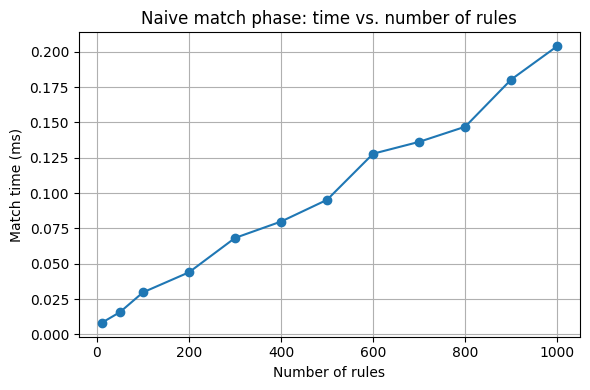

Saved plot to match_time_scaling.png


In [284]:
# Optional: plot rules vs. match time to visualise the (roughly linear) growth
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.plot(sizes, [t * 1000 for t in timings], marker="o")
plt.xlabel("Number of rules")
plt.ylabel("Match time (ms)")
plt.title("Naive match phase: time vs. number of rules")
plt.grid(True)
plt.tight_layout()
plt.savefig("match_time_scaling.png", dpi=120)
plt.show()
print("Saved plot to match_time_scaling.png")


### Why RETE Exists

The timing shows match time growing roughly **linearly with the number of rules** (and it would
grow further with more conditions per rule) — because the naive algorithm re-examines *every*
rule's *every* condition against WM on *every* cycle, even though usually only a **single fact**
changed between one cycle and the next.

The **RETE algorithm** (Forgy, 1979) fixes this by:

1. **Building a persistent network** of nodes representing shared conditions across rules, once,
   ahead of time — so common sub-patterns are matched only once even if many rules use them.
2. **Incremental (delta) matching**: instead of re-matching all rules from scratch, RETE only
   propagates the WM *change* (a fact added or removed) through the network, updating just the
   parts of the conflict set affected by that change.
3. **Caching partial matches** at each network node, so that partial results computed in earlier
   cycles are reused rather than recomputed.

The practical effect is that match cost per cycle becomes proportional to the **size of the
change**, not the size of the whole rule base — which is what makes production systems with
thousands of rules (expert systems like XCON, CLIPS, Drools, Jess) tractable in practice, where a
naive re-match-everything approach like ours would not scale.


## Summary

- We represented domain knowledge as IF–THEN **production rules** (`Rule` objects).
- We held facts in a **working memory** (a Python `set`).
- We implemented the **match phase**: a rule is applicable (enters the **conflict set**) when all
  its conditions are in WM and its conclusion is not already there (**refractoriness**).
- We ran a manual **recognise–act cycle**, watching the conflict set evolve as facts were derived.
- **Exercise 1** showed the conflict set growing/shrinking as facts are added one at a time.
- **Exercise 2** extended the matcher to support `NOT fact` negated conditions.
- **Exercise 3** measured how match time scales with the number of rules, and related the roughly
  linear growth of the naive matcher to the motivation behind the **RETE algorithm**, which avoids
  full re-matching by incrementally propagating only WM changes through a persistent match network.
